# Recover a stellar atmosphere from real Vesta-reflected solar light

## Problem

**Observation:**52570 real HERMES flux/wavelength samples in218 Fe-model regions. **Unknown:** effective temperature, logarithmic gravity, solar-scaled metallicity and an effective rotation-profile width. These quantities alter the measured absorption-line strengths and profiles; this is a model-based inverse problem.

**GT:** no independent physical ground-truth array is asserted. We compare with two separately completed original full MCMC runs and their identified standard-method result. Conditional posterior uncertainty is not proof of physical accuracy. With macroturbulence fixed to zero, the inferred width must not be equated with a separately measured true projected rotation.

In [1]:
from pathlib import Path
import sys,time,json,importlib.util
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=Path.cwd()
if not (ROOT/'src').is_dir(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.main import run
from src.visualization import review_figures
with np.load(ROOT/'data/raw_data.npz',allow_pickle=False) as z:
    measured={k:z[k][0] for k in ['wavelength','flux','uncertainty','ranges','masks']}
print('Real selected spectral channels:',len(measured['wavelength']))
print('Full source windows / analysis masks:',len(measured['ranges']),len(measured['masks']))
print('Initial author error / measured flux, median:',np.median(measured['uncertainty']/measured['flux']))

Real selected spectral channels: 52570
Full source windows / analysis masks: 218 177
Initial author error / measured flux, median: 0.01


## Data

The source paper identifies real HERMES observations from the1.2m Mercator telescope at resolving power85000, including a solar spectrum observed through reflected light from Vesta. The supplied author file is already reduced and shifted to the rest frame. We bind **every original read-spectrum output channel in all218 Fe windows**, retaining measured flux and the supplied initial errors. This is **author-real-processed** data, not native instrument counts and not a simulated observation. The initial error column is approximately1% of flux; it is not claimed to be an independently measured photon-noise variance.

The independent2002-node,350-component MARCS/PCA library is a forward-model calibration. Known static sampling/instrument matrices can be rebuilt from that library and public wavelength coordinates alone. They contain no observed flux, estimated stellar parameters, inferred residual-error map or posterior. The177 author masks select3643 concatenated Fe entries for atmospheric fitting; they do not license hiding full-window residuals. Only the original selected acquisition is scored, not the paper's separate35-star population study.

## Physics

Let atmospheric coordinates be $\phi=(t,g,m)$, with temperature t in kilokelvin, logarithmic cgs gravity g and solar-scaled logarithmic metallicity m. Interpolate library weights c inside a rescaled three-dimensional Delaunay tetrahedron, then evaluate

$$S_\lambda(\phi)=\mu_\lambda+s_\lambda\sum_r c_r(\phi)E_{r\lambda}.$$

Here mu, s and E are the independent mean, standardization scale and eigenspectra. Rotation with effective speed v and fixed limb coefficient.6 broadens the intrinsic spectrum; a Gaussian represents the fixed resolving power85000. Cubic sampling maps the result to measured wavelengths, preserving the original finite unit-continuum boundaries and half-pixel kernel convention. A nuisance continuum scale a is inferred separately in each window:

$$Y_j=a_w\,\mathcal P_w\mathcal G_R\mathcal V_v[S(\phi)]_j+\epsilon_j.$$

Y is observed author-unit flux, P is wavelength sampling, G instrumental broadening, V the rotation profile, w a spectral window and epsilon noise plus spectral-model discrepancy. Temperature, gravity and metallicity are coupled through line formation; neglected motions and blends create model bias.

## Method

The active computation uses only cleaned local modules. Two pairs of robust Huber trust-region least-squares fits initialize the atmosphere and estimate a wavelength-dependent discrepancy map from measured/model residuals. **That map is recomputed at runtime**; it is not public independent calibration. The original source's configuration mutation makes the second preliminary fit start at the first result, a convention explicitly preserved here.

The selected likelihood is

$$\log P=-\frac12\sum_j\left[\frac{(Y_j-F_j)^2}{\eta_j^2}+\log(\eta_j^2)\right]$$

inside the supplied parameter bounds. F is the current model, and eta is the actually estimated source-map uncertainty. The omitted Gaussian constant does not affect sampling. The2026 source has a Gaussian error-map extension with two disclosed limitations: filtered wavelengths are ranked against an unfiltered residual array, and a calculated error floor is unused. These source conventions are retained and independently diagnosed; they are not attributed to the2022 paper's simpler variance description.

The explicit affine-invariant ensemble uses16walkers,100burn sweeps and **all1000production sweeps**. With dimension d=4, a complementary walker c and current walker s, draw a=2 stretch factor $z=[(a-1)U+1]^2/a$, propose $q=c-(c-s)z$, and accept with log ratio $(d-1)\log z+\log P(q)-\log P(s)$. Two randomized groups are updated sequentially. The complete protocol is executed below, including fresh preliminary fits and noise inference.

Numerical fidelity matters: finite-difference early stopping was sensitive to tiny arithmetic changes. Preliminary fits/error estimation therefore use an explicitly local **source-order** spectral path. Nongradient MCMC uses separately validated equivalent known-operator algebra. The two original complete runs used NumPy2.0; deterministic original stages were independently recaptured under the shared NumPy2.4 backend before matching source-order code. We do not claim an unexecuted complete original2.4 MCMC run.

In [2]:
started=time.perf_counter()
def progress(phase,number,maximum):
    if number%100==0: print(phase,number,'maximum log probability',maximum,flush=True)
prediction,diagnostics,model,reconstruction_seconds=run(ROOT,progress=progress)
spec=importlib.util.spec_from_file_location('standalone_stellar_judge',ROOT/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report=judge.evaluate(ROOT/'output/reconstruction.npz')
print('Fresh complete reconstruction seconds:',reconstruction_seconds)
print(json.dumps(report,indent=2))
assert report['passed']
with np.load(ROOT/'notebooks/reference_outputs/upstream_measurements.npz',allow_pickle=False) as z:
    upstream={k:z[k].copy() for k in z.files}
with np.load(ROOT/'evaluation/baseline_reference.npz',allow_pickle=False) as z:
    reference_scale=z['parameter_scale'][0]
rows=['| Parameter | Fresh local | Reproduced original | Original posterior σ |','| --- | ---: | ---: | ---: |']
names=['Temperature (K)','log gravity (dex)','Metallicity (dex)','Effective width (km/s)']
for i,name in enumerate(names):
    rows.append('| '+name+' | '+format(prediction['reconstruction'][0,i],'.8g')+' | '+format(upstream['reconstruction'][0,i],'.8g')+' | '+format(reference_scale[i],'.8g')+' |')
display(Markdown(chr(10).join(rows)))
print('Full production chain shape:',diagnostics['chain'].shape)
print('Mean acceptance fraction:',diagnostics['acceptance_fraction'].mean())

burn 100 maximum log probability -21912.647047163307
production 100 maximum log probability -21912.616524541383
production 200 maximum log probability -21912.444897444675
production 300 maximum log probability -21912.282079434528
production 400 maximum log probability -21912.51596743236
production 500 maximum log probability -21912.387132442236
production 600 maximum log probability -21912.246885231074
production 700 maximum log probability -21912.37501507501
production 800 maximum log probability -21912.20543016878
production 900 maximum log probability -21912.157750088143
production 1000 maximum log probability -21912.077137125478
Fresh complete reconstruction seconds: 2034.6227286000503
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "parameter_standardized_max": 2.0155148763432598,
    "spectrum_nrmse": 0.00013696118399269888,
    "masked_weighted_rmse": 0.6611445318102673
  },
  "thresholds": {
    "parameter_standardized_max": {
      "comparison": "<=",
      "boundar

| Parameter | Fresh local | Reproduced original | Original posterior σ |
| --- | ---: | ---: | ---: |
| Temperature (K) | 5716.8167 | 5730.9861 | 9.5843742 |
| log gravity (dex) | 4.3420582 | 4.3748844 | 0.016286722 |
| Metallicity (dex) | -0.08033942 | -0.072580545 | 0.0064752013 |
| Effective width (km/s) | 3.6946438 | 3.6990315 | 0.028763739 |

Full production chain shape: (16, 1000, 4)
Mean acceptance fraction: 0.5876250000000001


## Results

Every plotted fresh spectrum and posterior below comes from the just-completed inverse. Original reproduced results are labeled separately. We inspect the complete wavelength regions and their residuals, distributed line details including the paper's6335/6336angstrom features, all four correlated posterior coordinates and the full1000production-sweep traces. The displayed line subset is for presentation only; the inverse and evaluation retain their complete declared data.

The parameter-response experiment actually recomputes eight spectra at plus/minus one reference-posterior standard deviation. This is model sensitivity on the same real acquisition, not a new synthetic measurement or an alternative fitted result. The noise experiment independently recomputes an aligned-ranking diagnostic; changed residual weights are not independent evidence of a better physical fit.

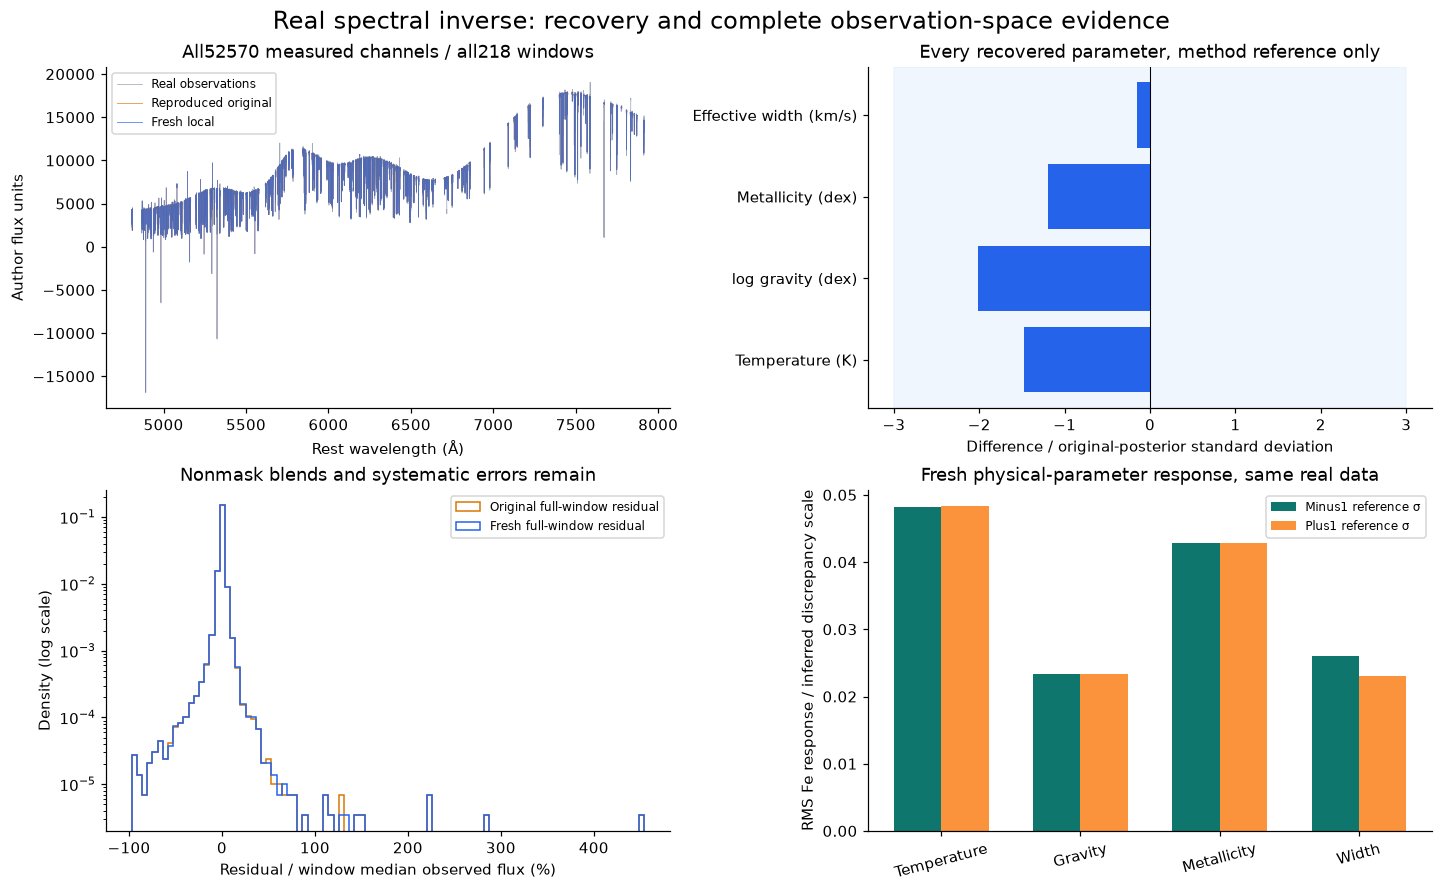

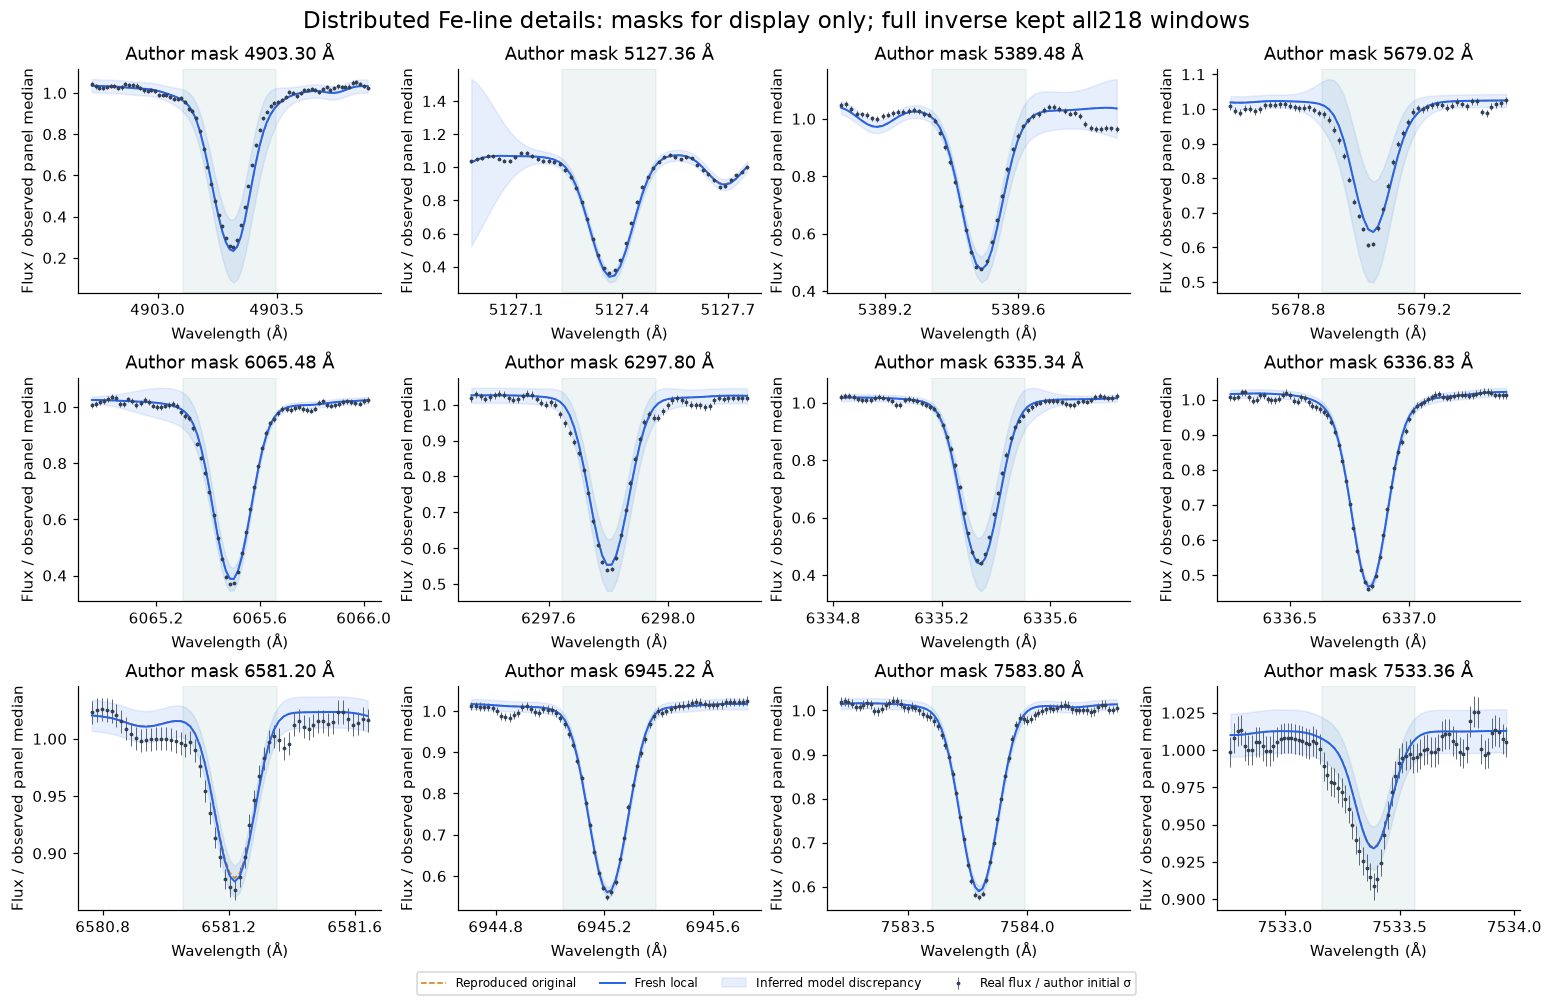

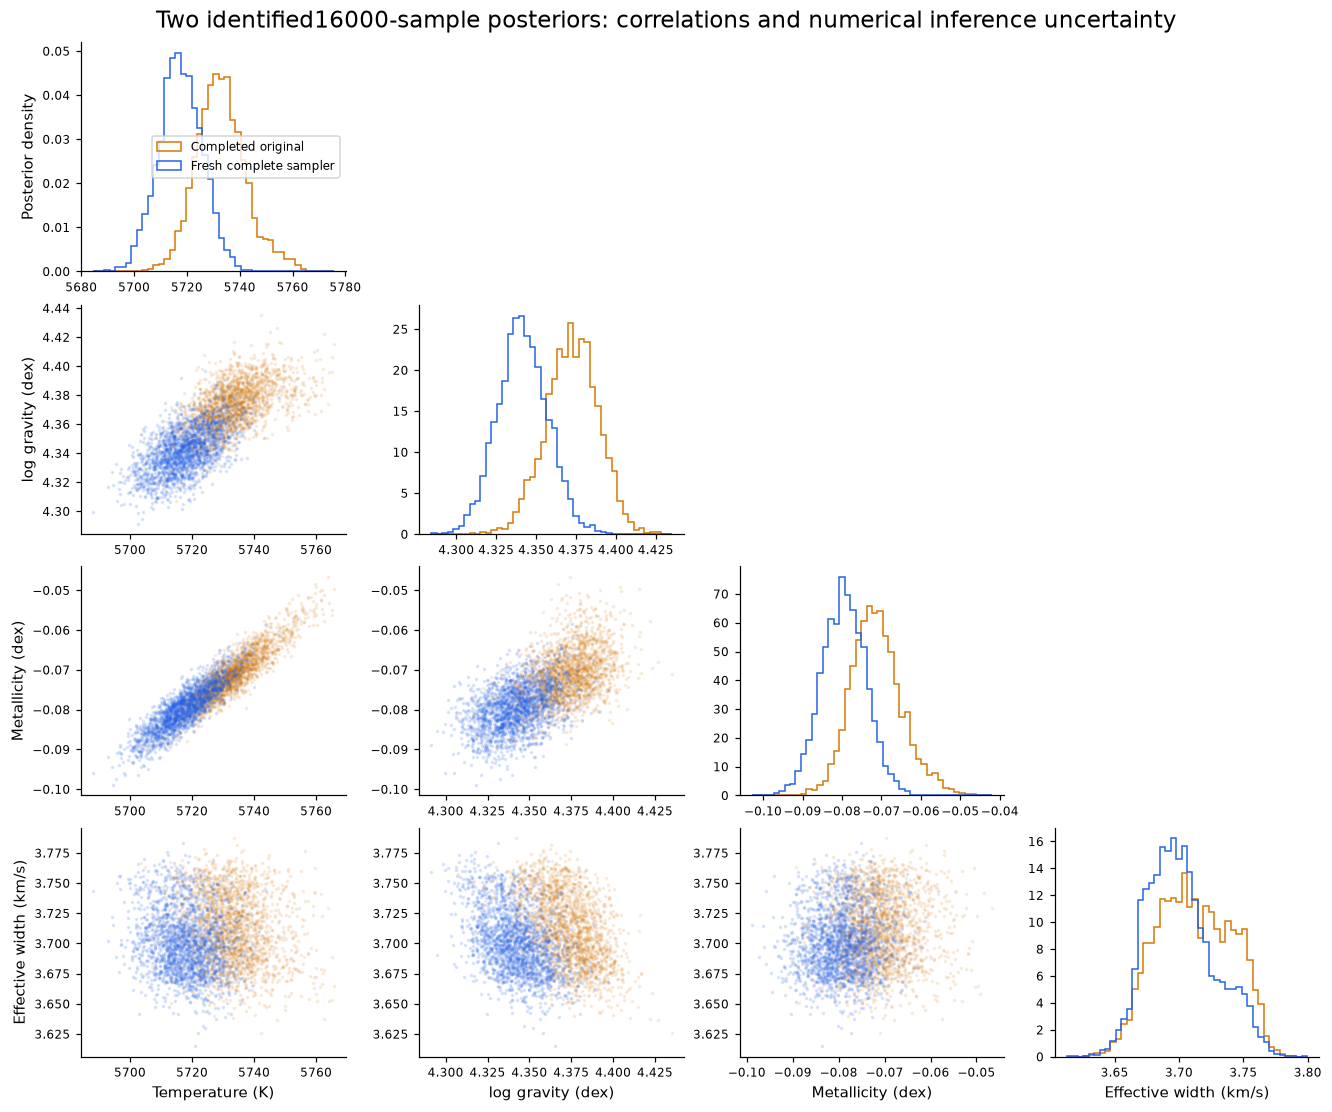

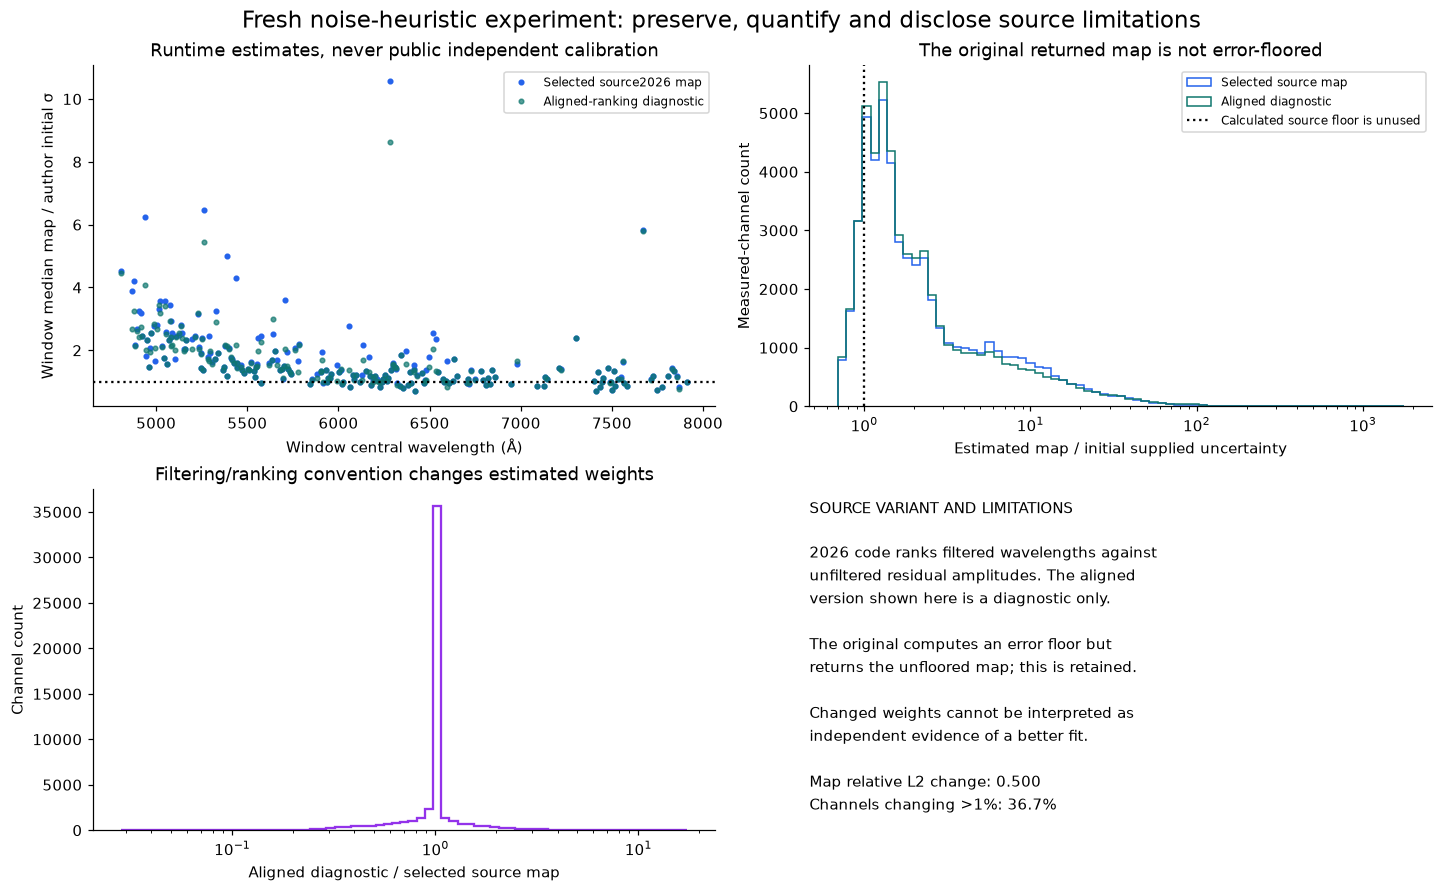

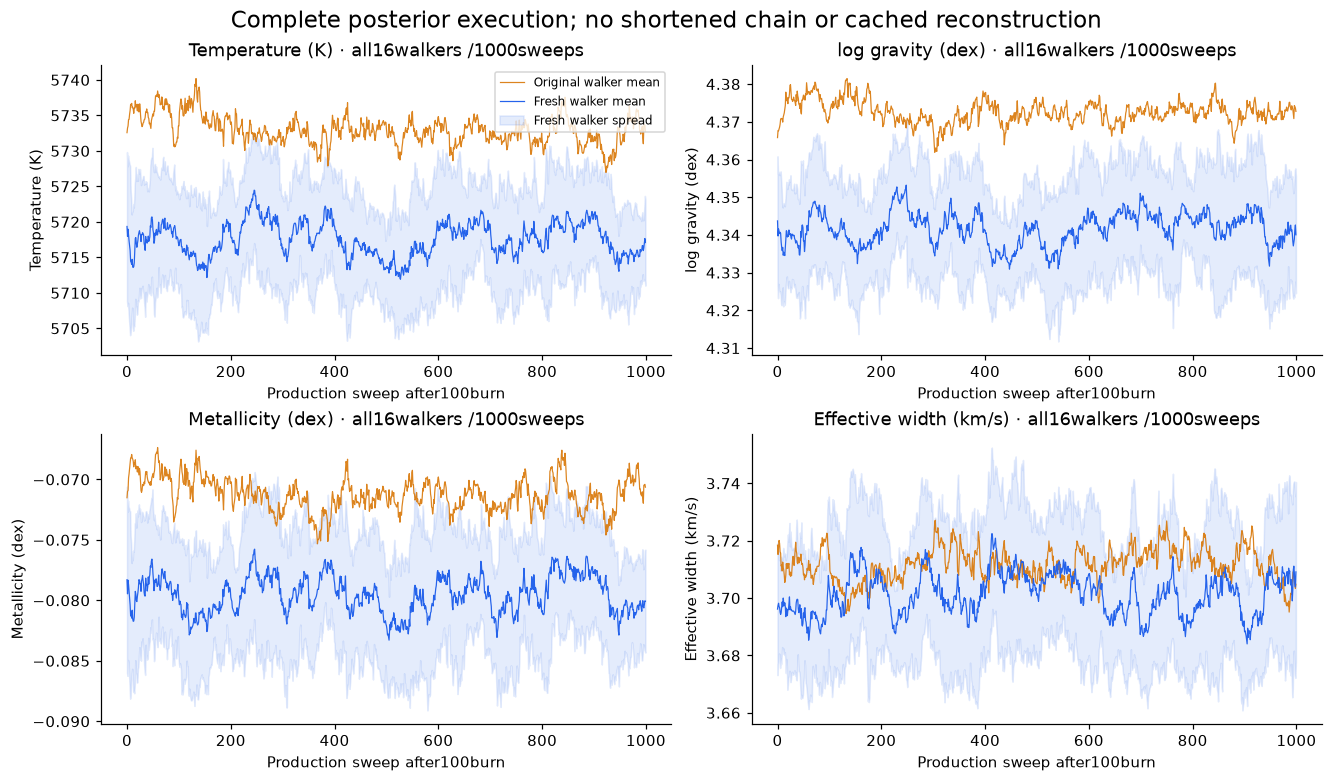

Fresh source-heuristic versus aligned diagnostic statistics:
{
  "original_weighted_rmse": 0.6611445318102673,
  "fresh_source_weighted_rmse": 0.6632343593146683,
  "aligned_diagnostic_weighted_rmse": 0.6891853776243846,
  "map_relative_l2": 0.49989215305748785,
  "fraction_changed_above_one_percent": 0.36703443028343163,
  "fraction_unfloored_below_initial": 0.12609853528628495,
  "source_peak_count": 1037,
  "aligned_peak_count": 980
}
Fresh masked spectral response at -1/+1 reference-posterior sigma:
[[0.04825808 0.04831352]
 [0.02331735 0.02328203]
 [0.04286962 0.04287466]
 [0.02608903 0.02303435]]
Separately identified original-source2.0 noise experiment relative L2 change: 0.4970973610490347
This original-source experiment is not relabeled as a fresh reconstruction.
Fresh complete-window relative RMS: 0.058822902946580546
Input uncertainty represents an author initial assumption, not verified instrumental noise.


In [3]:
figures,experiments=review_figures(model,prediction,diagnostics,upstream,reference_scale)
# Presentation only: readable wavelength ticks and the correct density ordinate.
from matplotlib.ticker import MaxNLocator
for axis in figures[1].axes:
    if axis.axison: axis.xaxis.set_major_locator(MaxNLocator(nbins=3))
figures[2].axes[0].set_ylabel('Posterior density')
for figure in figures:
    display(figure)
    plt.close(figure)
print('Fresh source-heuristic versus aligned diagnostic statistics:')
print(json.dumps(experiments['diagnostic_statistics'],indent=2))
print('Fresh masked spectral response at -1/+1 reference-posterior sigma:')
print(experiments['response_masked_rms'])
with np.load(ROOT/'notebooks/reference_outputs/upstream_noise_diagnostic.npz',allow_pickle=False) as z:
    historical_noise_change=np.linalg.norm(z['aligned_map']-z['original_map'])/np.linalg.norm(z['original_map'])
print('Separately identified original-source2.0 noise experiment relative L2 change:',historical_noise_change)
print('This original-source experiment is not relabeled as a fresh reconstruction.')
mask=model.mask_indices
relative_window_rms=np.sqrt(np.mean((model.raw['flux']-prediction['spectrum'][0])**2))/np.median(model.raw['flux'])
print('Fresh complete-window relative RMS:',relative_window_rms)
print('Input uncertainty represents an author initial assumption, not verified instrumental noise.')

## Conclusion

This notebook actively reconstructs the bound real spectrum through the full published-family inverse: local physical synthesis/broadening, robust preliminary fits, runtime discrepancy estimation and complete posterior sampling. It evaluates every recovered parameter and the entire52570-point spectrum, retaining both selected-line evidence and full-window model limitations.

Numerical method-reference agreement does not remove spectral-model bias. Nonmask blends, continuum conventions, the2026 noise heuristic and fixed-zero macroturbulence limit physical interpretation. The aligned-ranking diagnostic exposes substantial uncertainty-model sensitivity; it is not substituted for the selected source method. Conditional posterior precision is explicitly separated from independent physical GT, which is unavailable here.

The paper's multi-star validation and injected-noise campaign remain historical context, not fresh results of this single-real-acquisition benchmark. Fresh comparisons here preserve the task-relevant spectral details, original-method comparison, noise analysis, parameter sensitivity and complete sampling evidence without inventing missing experiments.

**Finite-window numerical limitation:** the reproduced original and fresh complete model each contain 13 negative spline-extrapolation boundary spikes among 52570 model entries; every one lies outside the 3643 Fe-line likelihood entries. These are retained in the full-spectrum comparison and shown without clipping. They are numerical model artifacts, not negative measured photon intensities or physical ground truth. Complete relative RMS residual remains about5.88%; the selected-mask weighted RMS is about0.66.
